# Verra Proponents 所屬國家 — 世界地圖

讀取 `Geography analysis.ipynb` 產生的 `proponents_by_country.csv`(每列 = 一家公司 × 一個所屬國家,持股對半的兩國都算),用 cartopy 畫世界地圖。

**步驟**
- Step 1 載入套件與資料
- Step 2 每國統計(專案數、公司數)
- Step 3 設定區(想改圖就改這裡)
- Step 4 對應國名並載入國界資料
- Step 5 畫圖並存檔

## Step 1. 載入套件與資料

In [1]:
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LogNorm, Normalize

HERE = Path.cwd()
# 資料夾結構:code/(程式) data/(csv) Photo/(圖);不管從 code 或上層資料夾開 notebook 都會找到正確位置
ROOT = HERE.parent if HERE.name == "code" else HERE
CODE, DATA, PHOTO = ROOT / "code", ROOT / "data", ROOT / "Photo"
DATA.mkdir(exist_ok=True); PHOTO.mkdir(exist_ok=True)
df = pd.read_csv(DATA / "proponents_by_country.csv")
df.head()

,Proponents,n_projects,project_countries,home_country,confidence,method,note
0,"Henan BCCY Environmental Energy CO.,LTD. (PP)",34,Mainland China,Mainland China,M,web search: company location found,"Henan BCCY Environmental Energy, HQ Zhengzhou ..."
1,G K Energy Marketers Pvt. Ltd,25,India,India,M,web search: company location found,"GK Energy, Pune (registered office)"
2,EKI Energy Services Limited (PP),20,Bangladesh|India|Kenya|Malawi,India,H,web research (largest shareholder),"Promoters ~66% (Dabkara family), Indian listed..."
3,Korea Carbon Management Ltd (PP),14,Fiji|Viet Nam|Zambia,South Korea,H,manual,NaN
4,Clean Air Action Corporation (PP),11,India|Kenya|Uganda,United States,L,web research (largest shareholder),Ownership not found online; believed US (TIST ...


## Step 2. 每國統計
- `projects`:該國公司擁有的專案數合計
- `companies`:該國公司數(同一家公司只算一次)

In [2]:
counts = (df.groupby("home_country")
            .agg(projects=("n_projects", "sum"), companies=("Proponents", "nunique"))
            .sort_values("projects", ascending=False))
counts.head(15)

,projects,companies
home_country,,
Mainland China,404,292
India,303,194
Turkey,123,88
United States,91,58
Brazil,52,38
United Kingdom,28,14
Canada,26,16
Viet Nam,18,13
Singapore,18,14


## Step 3. 設定區(想改圖就改這一格)
- `METRIC`:`"projects"`(專案數)或 `"companies"`(公司數)
- `LOG_SCALE`:中國 405 對多數國家個位數,用 log 色階才看得出差異
- `EXTENT`:`[經度小, 經度大, 緯度小, 緯度大]`;預設去掉南極
- `SHOW_SMALL_MARKERS`:新加坡、盧森堡等小國在地圖上看不到,設 `True` 會用圓點標出

In [3]:
METRIC = "projects"            # "projects" 或 "companies"
CMAP = "YlOrRd"
LOG_SCALE = True
FIGSIZE = (16, 8.5)
EXTENT = [-180, 180, -58, 85]
PROJECTION = ccrs.Robinson()
NO_DATA_COLOR = "#e6e6e6"
OCEAN_COLOR = "#eef3f8"
TITLE = "Where Verra project proponents are based"
SHOW_SMALL_MARKERS = False
SAVE_AS = PHOTO / "geography_map.png"

## Step 4. 對應國名並載入國界資料
Natural Earth 的國名和我們的寫法不同時,在 `NE_NAMES` 補對照;下面會印出沒對到的國家。

In [4]:
NE_NAMES = {
    "United States": "United States of America",
    "Mainland China": "China",
    "Viet Nam": "Vietnam",
    "Tanzania": "United Republic of Tanzania",
    "Congo (Democratic Republic of)": "Democratic Republic of the Congo",
    "Congo": "Republic of the Congo",
    "Bahamas": "The Bahamas",
    "Côte d'Ivoire": "Ivory Coast",
}
values = {NE_NAMES.get(c, c): v for c, v in counts[METRIC].items()}

# 第一次執行會自動下載 50m 國界資料(需要網路)
shp = shpreader.natural_earth(resolution="50m", category="cultural", name="admin_0_countries")
records = [r for r in shpreader.Reader(shp).records() if r.attributes["ADMIN"] != "Antarctica"]

unmatched = set(values) - {r.attributes["ADMIN"] for r in records}
print("沒對到 Natural Earth 的國家:", unmatched or "無")

沒對到 Natural Earth 的國家: 無


## Step 5. 畫圖並存檔

/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


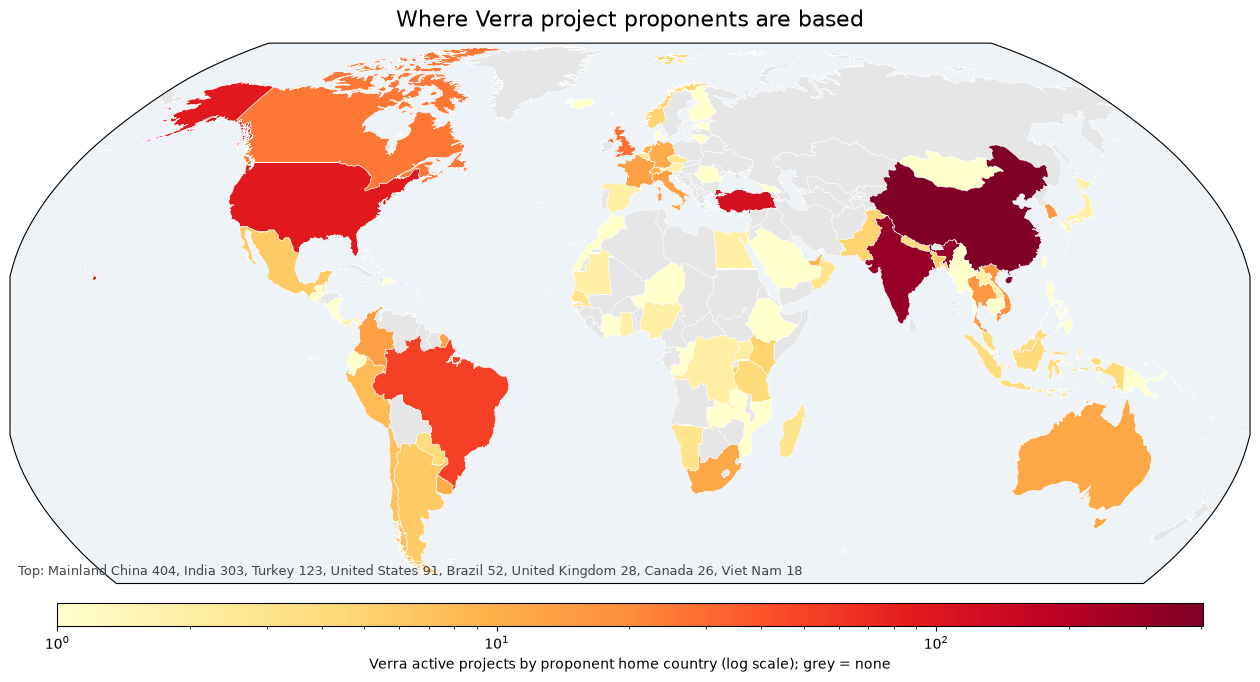

In [5]:
vmax = counts[METRIC].max()
norm = LogNorm(vmin=1, vmax=vmax) if LOG_SCALE else Normalize(vmin=0, vmax=vmax)
# norm =  Normalize(vmin=0, vmax=vmax)

cmap = plt.get_cmap(CMAP)

fig = plt.figure(figsize=FIGSIZE)
ax = plt.axes(projection=PROJECTION)
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
ax.set_facecolor(OCEAN_COLOR)

# 逐國上色:有資料用色階,沒資料用灰色
for r in records:
    v = values.get(r.attributes["ADMIN"])
    ax.add_geometries([r.geometry], ccrs.PlateCarree(),
                      facecolor=cmap(norm(v)) if v else NO_DATA_COLOR,
                      edgecolor="white", linewidth=0.4)

# 小國圓點(經度, 緯度 為大約位置)
if SHOW_SMALL_MARKERS:
    small = {"Singapore": (103.8, 1.35), "Luxembourg": (6.1, 49.8),
             "Bahamas": (-77.4, 25.0), "Mauritius": (57.5, -20.3)}
    for c, (lon, lat) in small.items():
        if c in counts.index:
            ax.scatter(lon, lat, s=60, transform=ccrs.PlateCarree(), zorder=5,
                       c=[cmap(norm(counts.loc[c, METRIC]))], edgecolors="black", linewidths=0.6)

# 色階條、標題、前幾名文字
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.035, pad=0.03, aspect=50)
cb.set_label(f"Verra active {METRIC} by proponent home country"
             + (" (log scale)" if LOG_SCALE else "") + "; grey = none")
ax.set_title(TITLE, fontsize=16, pad=12)
top = counts[METRIC].head(8)
fig.text(0.13, 0.17, "Top: " + ", ".join(f"{c} {int(v)}" for c, v in top.items()),
         fontsize=9, color="#444")

# fig.savefig(SAVE_AS, dpi=200, bbox_inches="tight")
plt.show()

---
## Step 6. 五大洲公司數長條圖
把每個國家歸到五大洲(亞洲、歐洲、非洲、美洲、大洋洲),統計各洲的**公司數**,畫成 5 根垂直長條,由多到少排列。

- 美洲(北美 + 南美)合併成一個洲,所以是五大洲。
- 土耳其、喬治亞歸亞洲。
- 同一家公司在同一洲內只算一次(持股對半的兩國若在同一洲,不會重複計算);跨洲的對半公司在兩個洲各算一次。

In [6]:
# Step 6-1. 國家 → 五大洲
CONTINENT = {
    "Asia": ["Bangladesh", "Cambodia", "Mainland China", "Georgia", "India", "Indonesia", "Israel", "Laos",
             "Malaysia", "Mongolia", "Myanmar", "Nepal", "Oman", "Pakistan", "Philippines",
             "Saudi Arabia", "Singapore", "South Korea", "Taiwan", "Thailand", "Turkey",
             "United Arab Emirates", "Viet Nam"],
    "Europe": ["Austria", "Belgium", "Czechia", "Denmark", "Estonia", "Finland", "France", "Germany",
               "Iceland", "Italy", "Lithuania", "Luxembourg", "Netherlands", "Norway", "Romania",
               "Spain", "Switzerland", "United Kingdom"],
    "Africa": ["Burundi", "Congo", "Congo (Democratic Republic of)", "Côte d'Ivoire", "Djibouti",
               "Egypt", "Ethiopia", "Ghana", "Kenya", "Madagascar", "Mauritania", "Mauritius",
               "Morocco", "Mozambique", "Namibia", "Niger", "Nigeria", "Senegal", "South Africa",
               "Tanzania", "Uganda", "Zambia"],
    "Americas": ["Argentina", "Bahamas", "Belize", "Brazil", "Canada", "Chile", "Colombia",
                 "Costa Rica", "Dominican Republic", "Ecuador", "Guatemala", "Mexico", "Nicaragua",
                 "Panama", "Paraguay", "Peru", "United States", "Uruguay"],
    "Oceania": ["Australia", "Papua New Guinea"],
}
country_to_continent = {c: cont for cont, cs in CONTINENT.items() for c in cs}

df["continent"] = df["home_country"].map(country_to_continent)
print("沒歸到洲的國家:", sorted(df.loc[df["continent"].isna(), "home_country"].unique()) or "無")

沒歸到洲的國家: ['Japan']


In [7]:
# Step 6-2. 各洲公司數(同一洲內每家公司只算一次)
continent_counts = (df.dropna(subset=["continent"])
                      .groupby("continent")["Proponents"].nunique()
                      .sort_values(ascending=False))
continent_counts

continent
Asia        660
Americas    175
Europe       80
Africa       53
Oceania      11
Name: Proponents, dtype: int64

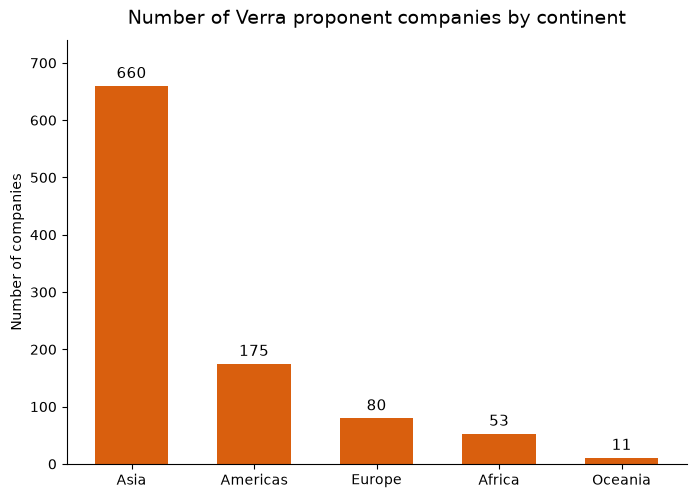

In [8]:
# Step 6-3. 垂直長條圖(想改顏色、標題、字體,改這裡)
BAR_COLOR = "#d95f0e"
BAR_TITLE = "Number of Verra proponent companies by continent"

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(continent_counts.index, continent_counts.values, color=BAR_COLOR, width=0.6)
ax.bar_label(bars, padding=3, fontsize=11)               # 長條上方顯示數字
ax.set_ylabel("Number of companies")
ax.set_title(BAR_TITLE, fontsize=14, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, continent_counts.max() * 1.12)
fig.savefig(PHOTO / "continent_company_counts.png", dpi=200, bbox_inches="tight")
plt.show()